# Stage 3: the words

**The question.** Does what a video says and shows in writing predict its lift, beyond stage 2's best baseline?
`lift` is stage 1's target: the video's log share rate minus the median of its creator's last 30 videos posted at
least 14 days earlier. Stage 2's best baseline is **B3 ridge**, metadata in ridge regression with no hour, which beat
zero lift for seen creators by 0.0007 log10, all of it from the video's length. This stage starts from B3 and asks
what the words add.

The text fields, all fixed when the video is posted (rule 4):

| Field | What it is | Written by |
|---|---|---|
| Caption | the creator's caption, hashtags included | the creator |
| Transcript | the spoken words, in English | Whisper, translated where the video isn't in English |
| Hook, body, payoff | the script split in three | a language model, from the transcript (or, when nobody speaks, from the on-screen text and scene) |
| On-screen text | the text read off sampled frames | a vision-language model (trap 5) |
| Scene description | what happens in the picture | the same vision-language model (trap 5) |

The scene description is a feature, not a fact: it is a model's reading of the frames, so it may carry the picture
more than the words. The notebook keeps it apart from the rest ("the words") for that reason.

Two kinds of text features, each with the same two heads (ridge on lift, logistic regression on breakout):

- **TF-IDF**: words and word pairs, weighted up when rare across videos and down when common, fitted on the
  training rows only. Sparse, linear, and every weight can be read.
- **Sentence embeddings**: `BAAI/bge-small-en-v1.5`, a small English encoder (33M parameters, 384 numbers per text)
  that runs on this laptop's CPU and that my content platform already uses.

The code is in `src/sharerate/text.py` (the vocabulary, TF-IDF and the embedding cache), with its tests in
`tests/test_text.py`. The loader's `load_videos(text=True)` returns the fields.

## 0. The bar, written before the first run (rule 7)

This cell was written, and committed, before any text model was fitted or scored.

- **The rows** are stage 2's: the 21,332 validation rows of `targets`, from 203 creators. Every text model predicts
  for every row: an empty field is a row of zeros, with a flag saying the field is empty, so no row is dropped and
  rule 5 holds without re-scoring on fewer rows.
- **The reference** is B3 ridge with no hour, refitted exactly as in notebook 02 (cell 24): MAE 0.3681 for seen
  creators. Zero lift (B0) and stage 2's best ranker (B1, the weighted mean with a half-life of 20) are shown beside
  it for context.
- **"On top of the baseline."** The ridge head is fitted on the training rows to what B3 leaves (lift minus B3's
  prediction), and predicts B3 plus its own correction. The logistic head is fitted to breakout with B3's
  predicted lift as one of its inputs. Either way, what the text adds is measured against B3 itself.
- **The primary bar.** A text model (its ridge head) beats the baseline if the 95% paired creator-bootstrap interval of its
  validation MAE gain over B3 ridge (B3's MAE minus its own) lies above 0 for **seen** creators: 138 creators,
  13,646 videos. New creators (27, 2,275 videos) and held-out creators (38, 5,411) are reported and are not
  required to pass.
- **The secondary bar.** For the logistic head, the gain in breakout ROC-AUC over B3 ridge (its predicted lift
  used as the breakout score) has an interval above 0, and so does the gain in the top-10% share.
- **Reposts.** 73 seen-creator validation videos have an exact twin among the training videos (`has_twin`). A pass
  must hold with them removed too; a gain that needs them is memorised reposts, and is reported as a miss.
- **Embeddings against TF-IDF.** bge-small beats TF-IDF if the interval of its MAE gain over the all-fields TF-IDF
  ridge (both on top of B3) lies above 0 for seen creators. Only then does stage 4's rental run a larger text
  encoder; otherwise it runs no text job.
- **Fields one at a time,** and the words apart from the scene description, are descriptive: reported with
  intervals, to say where the signal is, not as extra chances to pass.
- **What goes to stage 5.** The passing model with the largest MAE gain for seen creators. If none passes, stage 5's
  combined model leaves text out, and this notebook says so.
- **Fixed in advance, never tuned:** the vocabulary (words and word pairs that at least 20 training creators use,
  with @mentions and links removed, so no feature is one creator's signature and every weight can be shown under
  rule 9); TF-IDF's settings (1 + log of the count, rows scaled to length 1, IDF from the training rows); the
  encoder (bge-small-en-v1.5, the first 256 tokens, unit-length vectors).
- **Chosen on validation,** over all 21,332 rows: the ridge penalty by MAE, the logistic penalty by ROC-AUC. The
  test split is never opened here; stage 5 opens it once.
- **A miss is a miss.** A gain whose interval touches 0 is reported as "the words add nothing beyond B3", never
  tuned until it passes. That result is publishable.
- **Intervals** come from 2,000 replicates that resample creators, with seed 2026, the same draws as stage 2.

## 1. The rows

**What.** Load the training and validation rows with their text fields (`data.load_videos(text=True)`), and every
library video's post time for B3's timing features. Check the counts against notebook 02.

**Why.** The same rows as stage 2, so every number here compares with notebook 02's. The text fields come back in the
same order as the other columns (`tests/test_data.py` checks it), so a text feature lines up with every stage 2
feature.

**The mistake it avoids.** Printing a caption or a transcript to see what it looks like. These are other creators'
words: they go into features and are never shown. Section 8 shows only words and word pairs that at least 20
creators use.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sharerate import data, history, text
from sharerate.bootstrap import paired_creator_bootstrap
from sharerate.metrics import METRICS, eligible_creators

SEED, N_BOOT = 2026, 2_000  # stage 2's seed: the same 2,000 creator draws
GROUPS = ["seen", "new", "holdout"]  # targets.creator_seen, rule 3's three ways
GROUP_NAMES = {"seen": "Seen creators", "new": "New creators (training group, no training rows)",
               "holdout": "Held-out creators"}
FIELDS = list(text.FIELDS)  # caption, transcript, hook, body, payoff, on-screen text, scene description
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

videos = data.load_videos(text=True)  # train and validation only; the text columns are never printed
posts = data.load_posting_times()  # when each target creator posted every library video (B3's timing features)
training = ((videos.time_split == "train") & (videos.creator_group == "train")).to_numpy()  # the only rows fitted on
validation = (videos.time_split == "validation").to_numpy()  # every setting is chosen here
val = videos[validation]
lift = videos.lift.to_numpy()
breakout = videos.breakout.to_numpy().astype(int)
creator = videos.creator.to_numpy()

print(f"{len(videos):,} rows from {videos.creator.nunique()} creators, splits: {sorted(set(videos.time_split))}")
print(f"Training: {training.sum():,} videos from {videos[training].creator.nunique()} creators")
print(f"Validation: {len(val):,} videos from {val.creator.nunique()} creators, breakout rate {val.breakout.mean():.3f}")
display(val.groupby("creator_seen").agg(creators=("creator", "nunique"), videos=("lift", "size"),
                                        with_a_twin_in_training=("has_twin", "sum")).loc[GROUPS])
# Notebook 02's counts: if these move, the rows are not stage 2's.
assert (training.sum(), videos[training].creator.nunique()) == (74_552, 148)
assert val.creator_seen.value_counts().to_dict() == {"seen": 13_646, "holdout": 5_411, "new": 2_275}

121,749 rows from 214 creators, splits: ['train', 'validation']
Training: 74,552 videos from 148 creators
Validation: 21,332 videos from 203 creators, breakout rate 0.242


,creators,videos,with_a_twin_in_training
creator_seen,,,
seen,138,13646,73
new,27,2275,3
holdout,38,5411,18


**What it says.** 121,749 training and validation rows from 214 creators; the test rows were not loaded. Models fit
on 74,552 videos from 148 creators. Validation holds 21,332 videos from 203 creators, with a breakout rate of 0.242:
13,646 from 138 seen creators, 2,275 from 27 new ones and 5,411 from 38 held-out ones, notebook 02's counts (the
asserts hold). 94 validation videos have an exact twin among the training videos: 73 of the seen creators', 3 of the
new ones' and 18 of the held-out ones'.

## 2. Coverage: which videos have each field

**What.** The share of videos whose field is not empty, in the training cell and in each validation group, and the
share the labelling pipeline marked wordless (no speech and no on-screen text). The test split stays closed, so its
coverage is not shown here; over all 143,489 target videos the counts match stage 1's (`tests/test_data.py`).

**Why.** A field that most videos lack can carry little, and an empty field may itself say something: a video
nobody speaks in is a different kind of video. A field whose coverage moves between training and validation also
warns that a model fitted on one may not carry to the other.

**The mistake it avoids.** Assuming every video has a transcript. About a fifth don't, and every model still has to
predict for them (rule 5): an empty field becomes a row of zeros plus a flag saying it is empty.

In [2]:
has = (videos[FIELDS] != "").to_numpy()  # True where the field holds any text
has_frame = pd.DataFrame(has, columns=[text.FIELDS[f] for f in FIELDS])
has_frame["Wordless (no speech, no on-screen text)"] = videos.is_wordless.eq(1).to_numpy()
coverage = pd.DataFrame({"training": has_frame[training].mean()})
for group in GROUPS:
    coverage[f"validation: {group}"] = has_frame[validation & (videos.creator_seen == group).to_numpy()].mean()
display((100 * coverage).round(1).astype(str) + "%")
print(f"Videos with no text in any of the six word fields: training {(~has[training, :6].any(axis=1)).mean():.1%}, "
      f"validation {(~has[validation, :6].any(axis=1)).mean():.1%}")

,training,validation: seen,validation: new,validation: holdout
Caption,93.4%,90.5%,81.0%,82.0%
Transcript,82.1%,78.3%,72.5%,78.3%
Hook,74.3%,72.5%,66.9%,72.1%
Body,62.3%,61.7%,56.1%,58.3%
Payoff,54.1%,51.6%,45.3%,46.9%
On-screen text,51.2%,71.9%,72.9%,67.1%
Scene description,99.6%,99.6%,96.9%,99.6%
"Wordless (no speech, no on-screen text)",7.0%,3.8%,4.1%,6.0%


Videos with no text in any of the six word fields: training 0.5%, validation 0.7%


**What it says.** Almost every video has a scene description (99.6% of training videos) and a caption (93.4%), and four
in five have a transcript (82.1%). The script split thins out toward the end: a hook for 74.3%, a body for 62.3%, a
payoff for 54.1%. Only 0.5% of training videos and 0.7% of validation ones have no text in any of the six word fields,
so almost no row rests on the scene description alone.

One field moves: on-screen text, on 51.2% of training videos and on 67.1% to 72.9% of each validation group. Wordless
videos fall from 7.0% to 3.8% for seen creators. The newer videos put text on screen more often, so the model meets
on-screen text more often than it learned from it. New creators' videos have most fields less often (a caption for
81.0%, a transcript for 72.5%, a scene description for 96.9%).

**What.** Two checks on what an empty field means.

1. **Does having a field go with lift?** Inside each creator: the lift of videos that have the field minus the lift
   of those that don't, on the training rows. It is the slope of a regression of lift on the flag with one intercept
   per creator, so a creator who always writes captions and happens to be growing doesn't make captions look good.
   The interval comes from 2,000 draws of creators.
2. **Is a field missing more often for clips the platform retired?** The share of training videos with each field,
   for clips whose file still exists and for retired ones (`data.load_leak_reference`, used here only as a check).

**Why.** The flags are features. If they go with lift, the model should have them. But the platform keeps each
channel's top clips by share rate (trap 3), so if retired clips had lost their fields, an empty field would mean
"retired" and the flag would be a leak.

**The mistake it avoids.** Letting survivorship in through a side door: not through the `files` table, which the
loader refuses, but through which clips got labelled.

In [3]:
def within_creator_gap(flag, rows):
    # Regression of lift on a 0/1 flag with one intercept per creator: sum((f - mean_c f) * lift) / sum((f - mean_c f)^2)
    # per creator, summed over the creators in a draw. A creator whose videos all have the flag (or all lack it)
    # adds nothing, as it should: there is nothing inside that creator to compare.
    codes, _ = pd.factorize(creator[rows])
    f = flag[rows].astype(float)
    centred = f - pd.Series(f).groupby(codes).transform("mean").to_numpy()
    top = np.bincount(codes, centred * lift[rows])  # per creator
    bottom = np.bincount(codes, centred ** 2)
    rng = np.random.default_rng(SEED)
    n = len(top)
    draws = np.stack([np.bincount(rng.integers(0, n, n), minlength=n) for _ in range(N_BOOT)])  # creators drawn
    replicates = (draws @ top) / (draws @ bottom)
    return top.sum() / bottom.sum(), *np.quantile(replicates, [0.025, 0.975])


kept = data.load_leak_reference().to_numpy().astype(bool)  # a check only: never a feature (trap 3)
checks = []
for j, field in enumerate(FIELDS + ["wordless"]):
    flag = has[:, j] if field != "wordless" else videos.is_wordless.eq(1).to_numpy()
    gap, low, high = within_creator_gap(flag, training)
    checks.append({
        "field": text.FIELDS.get(field, "Wordless"),
        "lift with it minus without, inside a creator": f"{gap:+.3f} [{low:+.3f}, {high:+.3f}]",
        "as share rate": f"{100 * (10 ** gap - 1):+.1f}%",
        "kept clips with it": f"{flag[training & kept].mean():.1%}",
        "retired clips with it": f"{flag[training & ~kept].mean():.1%}",
    })
display(pd.DataFrame(checks).set_index("field"))
print(f"Training rows: {(training & kept).sum():,} kept clips, {(training & ~kept).sum():,} retired")

,"lift with it minus without, inside a creator",as share rate,kept clips with it,retired clips with it
field,,,,
Caption,"-0.009 [-0.036, +0.043]",-2.0%,91.6%,94.1%
Transcript,"+0.009 [-0.013, +0.032]",+2.0%,82.4%,82.0%
Hook,"+0.017 [-0.002, +0.037]",+3.9%,75.0%,74.1%
Body,"+0.015 [-0.004, +0.035]",+3.5%,62.6%,62.2%
Payoff,"+0.008 [-0.010, +0.029]",+1.9%,58.2%,52.5%
On-screen text,"+0.061 [+0.030, +0.093]",+15.1%,52.7%,50.7%
Scene description,"+0.033 [-0.032, +0.106]",+8.0%,99.4%,99.7%
Wordless,"-0.034 [-0.079, +0.008]",-7.4%,7.5%,6.8%


Training rows: 20,350 kept clips, 54,202 retired


**What it says.** Inside a creator, only on-screen text goes with lift: videos that have it beat the same creator's videos
without it by +0.061 log10 [+0.030, +0.093], 15.1% in share rate. Every other interval includes 0, and wordless videos
lean lower (−0.034 [−0.079, +0.008]).

The flags are not a way in for survivorship: each field is about as common among retired clips as among kept ones,
within 2.5 points, except the payoff (58.2% of kept clips against 52.5% of retired ones). That gap pools all
creators, and having a payoff doesn't go with lift inside a creator (+0.008 [−0.010, +0.029]). The leak check after
section 7 tests the models themselves.

## 3. The reference: B3 ridge, refitted

**What.** Rebuild stage 2's B3 features (log duration, wordless, earlier videos, days since the previous one, the
weekday) and refit ridge with notebook 02's penalty (alpha 0.1, cell 24) on the training cell. Zero lift and stage
2's best ranker (B1, the weighted mean of the creator's settled rates, half-life 20 videos) sit beside it.

**Why.** Every text model is measured against B3 on the same rows, inside each bootstrap replicate. Refitting it
with the same code gives the same predictions notebook 02 scored, and the assert checks that it does.

**The mistake it avoids.** Comparing with a number copied from another notebook, or choosing B3's penalty again on
this notebook's runs. B3 is frozen as stage 2 left it.

In [4]:
timing = history.posting_features(videos, posts)
features = pd.DataFrame({
    "log_duration": np.log10(videos.duration_seconds.clip(lower=1)),  # 10 videos have a duration of 0
    "wordless": videos.is_wordless,  # NaN where the labelling pipeline never reached the video
    "log_earlier_videos": np.log10(1 + timing.earlier_videos),
    "log_days_since_previous": np.log10(1 + timing.days_since_previous),
    "weekday_utc": timing.weekday_utc,
})
NUMERIC = ["log_duration", "wordless", "log_earlier_videos", "log_days_since_previous"]
b3 = make_pipeline(
    ColumnTransformer([
        # A missing number becomes the training median plus a was-missing column; then everything is standardised.
        ("numbers", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUMERIC),
        ("categories", OneHotEncoder(handle_unknown="ignore"), ["weekday_utc"]),
    ]),
    Ridge(alpha=0.1),  # notebook 02's choice (cell 24), not chosen again
).fit(features[training], lift[training])

predictions = {  # one lift prediction per row of `videos`
    "B0 zero lift": np.zeros(len(videos)),
    "B3 ridge": b3.predict(features),
    # Stage 2's best ranker, for context: where it has too little history it predicts zero lift, as in notebook 02.
    "B1 weighted mean": np.nan_to_num(history.ewm_form(videos, half_life=20), nan=0.0),
}
scores = {}  # breakout scores from the logistic heads (ranking metrics only; they are not lifts)


def validation_mae(pred):
    # The number every ridge penalty is chosen by: MAE over all 21,332 validation rows.
    return np.abs(lift[validation] - pred[validation]).mean()


seen_rows = validation & (videos.creator_seen == "seen").to_numpy()  # the bar's rows
for name, pred in predictions.items():
    print(f"{name}: validation MAE {validation_mae(pred):.4f}, "
          f"seen creators {np.abs(lift[seen_rows] - pred[seen_rows]).mean():.4f}")
b3_seen = np.abs(lift[seen_rows] - predictions["B3 ridge"][seen_rows]).mean()
assert round(b3_seen, 4) == 0.3681  # notebook 02, cell 36

B0 zero lift: validation MAE 0.3712, seen creators 0.3687
B3 ridge: validation MAE 0.3706, seen creators 0.3681
B1 weighted mean: validation MAE 0.3693, seen creators 0.3662


**What it says.** B3 ridge refits to notebook 02's numbers: a validation MAE of 0.3706 overall and 0.3681 for seen
creators, and the assert holds. Zero lift misses by 0.3712 and 0.3687, and B1's weighted mean by 0.3693 and 0.3662.
Every gain from here on is measured from B3's 0.3681.

## 4. TF-IDF: the words, counted

**What.** For each field separately: the vocabulary of words and word pairs that at least 20 of the 148 training
creators use (`text.creator_vocabulary`), then TF-IDF weights fitted on the training rows (`text.fit_tfidf`), applied
to every row. In each video's row, a term weighs 1 + log(times it appears), times its IDF (higher for a term few
videos use), and the row is scaled to length 1.

**Why.**
- **One vocabulary per field,** because "wait" in a caption and "wait" in a payoff are different signals, and so
  each field can be tested alone.
- **At least 20 creators,** fixed before the run: a word only one creator uses is that creator's signature (their
  name, a catchphrase, a sponsor). Lift is already measured against the creator, so such a word would teach the
  model who made the video, not what works, and rule 9 could not show it.
- **Word pairs** catch what single words lose: "not funny" is not "funny".

**The mistake it avoids.** Fitting the vocabulary or the IDF on every row. Validation's words would then shape the
features the model is judged with. Here both come from the training cell only, and a validation word the training
creators never used is simply not a feature.

In [5]:
tfidf, vocabularies, sizes = {}, {}, []
for field in FIELDS:
    vectorizer, vocabularies[field] = text.fit_tfidf(videos.loc[training, field], creator[training])
    tfidf[field] = vectorizer.transform(videos[field])  # every row: sparse, one column per term
    terms = vocabularies[field].index
    sizes.append({
        "field": text.FIELDS[field],
        "terms": len(terms),
        "of which word pairs": sum(" " in term for term in terms),
        "terms per video (median, when not empty)": np.median(np.diff(tfidf[field].indptr)[has[:, FIELDS.index(field)]]),
        "validation videos with no term": f"{(np.diff(tfidf[field].indptr)[validation] == 0).mean():.1%}",
    })
display(pd.DataFrame(sizes).set_index("field"))

,terms,of which word pairs,"terms per video (median, when not empty)",validation videos with no term
field,,,,
Caption,1598,544,5.0,20.9%
Transcript,11912,8546,24.0,24.7%
Hook,3490,1989,10.0,29.2%
Body,6048,3747,19.0,40.4%
Payoff,4731,2912,14.0,51.3%
On-screen text,2097,948,10.0,31.1%
Scene description,9605,6397,35.0,0.7%


**What it says.** The 20-creator rule leaves 39,481 terms over the seven fields, from 1,598 in captions to 11,912 in
transcripts. Word pairs are most of the terms in the long fields (8,546 of the transcript's 11,912) and a third of the
caption's (544 of 1,598). A median non-empty transcript uses 24 known terms, a caption 5, a scene description 35.
Many validation texts give no term at all: 20.9% of captions and 51.3% of payoffs, but only 0.7% of scene
descriptions. Most of those fields are empty; the rest use only words that fewer than 20 training creators share.
Those rows rest on their flags.

**What.** The two heads, written once and used for every set of text features in this notebook:

- **Ridge on lift.** Fitted on the training rows to B3's residual (lift minus B3's prediction), on the field flags
  and the text features. The prediction is B3's plus the head's. Its penalty alpha is chosen by validation MAE.
- **Logistic regression on breakout.** Fitted on the training rows to breakout (lift of at least log10 2), on B3's
  predicted lift (standardised), the flags and the text features. Its score is the log-odds of a breakout; its
  penalty C (smaller is stronger) is chosen by validation ROC-AUC.

Then both heads on all seven fields' TF-IDF together.

**Why.** Fitting the ridge head to what B3 leaves means the text can only add to B3, and B3's length effect can't be
credited to words that go with length. The logistic head answers the breakout question directly, and B3's
prediction among its inputs gives it B3's ranking to start from.

**The mistake it avoids.** A text model that re-learns duration from words (long transcripts are long videos) and
reports it as a text gain. And for the logistic head, reading its probabilities as lifts: it is scored only on the
ranking metrics.

In [6]:
residual = lift - predictions["B3 ridge"]  # what B3 leaves: the ridge heads are fitted to this
b3_score = ((predictions["B3 ridge"] - predictions["B3 ridge"][training].mean())
            / predictions["B3 ridge"][training].std())[:, None]  # B3's prediction, standardised, as one column
RIDGE_ALPHAS = [3, 10, 30, 100, 300, 1_000, 3_000]
LOGISTIC_CS = [0.003, 0.01, 0.03, 0.1, 0.3]


def flag_columns(fields):
    # 1 where the field holds text: the flags let a model use "this video has on-screen text" by itself.
    return has[:, [FIELDS.index(f) for f in fields]].astype(np.float32)


def stack(blocks):
    # Sparse blocks (TF-IDF) stay sparse; dense ones (embeddings) are joined as one array.
    if any(sparse.issparse(b) for b in blocks):
        return sparse.hstack([sparse.csr_matrix(b) for b in blocks]).tocsr()
    return np.hstack(blocks)


def ridge_head(X, alphas=RIDGE_ALPHAS):
    # One fit per penalty on the training rows; keep the one whose B3 + head has the lowest validation MAE.
    by_alpha, best = {}, None
    for alpha in alphas:
        head = Ridge(alpha=alpha).fit(X[training], residual[training])
        pred = predictions["B3 ridge"] + head.predict(X)
        by_alpha[alpha] = validation_mae(pred)
        if best is None or by_alpha[alpha] < by_alpha[best[0]]:
            best = (alpha, head, pred)
    return best[0], best[1], best[2], pd.Series(by_alpha, name="validation MAE")


def logistic_head(X, Cs=LOGISTIC_CS):
    # B3's prediction goes in as the first column; keep the C with the highest validation ROC-AUC.
    X = stack([b3_score, X])
    by_C, best = {}, None
    for C in Cs:
        model = LogisticRegression(C=C, max_iter=3_000).fit(X[training], breakout[training])
        score = model.decision_function(X)  # the log-odds of a breakout: ranks the same as the probability
        by_C[C] = roc_auc_score(breakout[validation], score[validation])
        if best is None or by_C[C] > by_C[best[0]]:
            best = (C, model, score)
    return best[0], best[1], best[2], pd.Series(by_C, name="validation ROC-AUC")


X_tfidf = stack([flag_columns(FIELDS)] + [tfidf[f] for f in FIELDS])
alpha, tfidf_ridge, predictions["TF-IDF ridge"], by_alpha = ridge_head(X_tfidf)
C, tfidf_logistic, scores["TF-IDF logistic"], by_C = logistic_head(X_tfidf)
display(by_alpha.round(4).to_frame().T, by_C.round(4).to_frame().T)
print(f"TF-IDF ridge, all fields: alpha {alpha}, validation MAE {by_alpha[alpha]:.4f} "
      f"(B3: {validation_mae(predictions['B3 ridge']):.4f})")
print(f"TF-IDF logistic, all fields: C {C}, validation ROC-AUC {by_C[C]:.4f} "
      f"(B3: {roc_auc_score(breakout[validation], predictions['B3 ridge'][validation]):.4f})")

,3,10,30,100,300,1000,3000
validation MAE,0.3942,0.3758,0.3675,0.3649,0.3661,0.3683,0.3695


,0.003,0.010,0.030,0.100,0.300
validation ROC-AUC,0.5563,0.564,0.5654,0.5649,0.5628


TF-IDF ridge, all fields: alpha 100, validation MAE 0.3649 (B3: 0.3706)
TF-IDF logistic, all fields: C 0.03, validation ROC-AUC 0.5654 (B3: 0.5296)


**What it says.** All seven fields' TF-IDF on top of B3 brings the validation error from 0.3706 to 0.3649, with alpha
100, inside the grid: less shrinking overfits (0.3942 at alpha 3), more gives the gain back (0.3695 at 3,000). The
logistic head ranks breakouts at a ROC-AUC of 0.5654 with C 0.03, against 0.5296 for B3's predicted lift. Both
penalties were chosen on these rows, so section 6's paired intervals are what judge them.

**What.** The same two heads on one field at a time (its TF-IDF and its flag), and on the six word fields together
without the scene description ("the words"). Each gets its own penalty, chosen on validation the same way.

**Why.** To see which field carries the signal, and whether it is the words people wrote and said or the
vision-language model's description of the picture (trap 5).

**The mistake it avoids.** Reading the all-fields model's weights to say which field matters. Fields overlap (the
hook is part of the transcript), so a weight split between two fields can make both look weak. Fitting each alone
says what each can do by itself.

In [7]:
SUBSETS = {text.FIELDS[f]: [f] for f in FIELDS} | {"The words (six fields)": text.WORDS}
subset_choices = []
for name, fields in SUBSETS.items():
    X = stack([flag_columns(fields)] + [tfidf[f] for f in fields])
    alpha, _, predictions[f"TF-IDF ridge: {name}"], by_alpha = ridge_head(X)
    C, _, scores[f"TF-IDF logistic: {name}"], by_C = logistic_head(X)
    subset_choices.append({"fields": name, "alpha": alpha, "validation MAE": by_alpha[alpha],
                           "C": C, "validation ROC-AUC": by_C[C]})
display(pd.DataFrame(subset_choices).set_index("fields").round(4))

,alpha,validation MAE,C,validation ROC-AUC
fields,,,,
Caption,100,0.3696,0.03,0.5410
Transcript,30,0.3689,0.30,0.5382
Hook,30,0.3693,0.03,0.5419
Body,30,0.3697,0.03,0.5335
Payoff,30,0.3700,0.01,0.5297
On-screen text,30,0.3677,0.10,0.5645
Scene description,30,0.3671,0.10,0.5515
The words (six fields),100,0.3663,0.03,0.5603


**What it says.** Every field alone does better than B3's 0.3706. The two fields the vision-language model produced do
best: the scene description (0.3671) and the on-screen text (0.3677, which also has the best ROC-AUC of any single
field, 0.5645). The spoken fields follow (transcript 0.3689, hook 0.3693), then the caption and the body (0.3696,
0.3697), and the payoff is last (0.3700). The six word fields together reach 0.3663; with the scene description, all
seven reach 0.3649 (cell 18). The transcript's logistic head chose the weakest penalty in the grid, C 0.3: it is a
descriptive row, not a candidate, so the grid was left as it was.

## 5. Sentence embeddings: the words, read

**What.** Each field of each video through `BAAI/bge-small-en-v1.5` (`text.embed`): 384 numbers per text, of length
1, from its first 256 tokens. An empty field is 384 zeros. The vectors are cached on disk under `data/embeddings/`
(git-ignored) by the md5 of the text, so a text shared by two videos or two fields is embedded once.

**Why.** TF-IDF only knows the exact words it counted. An encoder trained on a billion sentence pairs puts "my cat
knocked it over" near "the dog ruined everything", so a pattern can be learned from both. bge-small is small enough
for this laptop's CPU, and my content platform already uses it.

**The mistake it avoids.** Embedding the test split's texts now. The cache holds the training and validation texts
only; the test texts are embedded in stage 5, when the test is opened. A separate run of `text.embed` over the same
texts filled the cache first: 550,823 distinct texts in 207 minutes (about 3.5 hours) on this laptop's CPU, 44 a
second, by its log. This cell only reads the cache.

In [8]:
embeddings = {field: text.embed(videos[field]) for field in FIELDS}  # rows x 384 each, zeros where empty
for field in FIELDS:
    lengths = np.linalg.norm(embeddings[field], axis=1)
    # Every non-empty field is a unit vector, every empty one is zeros: nothing in between.
    assert np.allclose(lengths[has[:, FIELDS.index(field)]], 1, atol=1e-3) and not lengths[~has[:, FIELDS.index(field)]].any()
print(f"{len(FIELDS)} fields x {embeddings[FIELDS[0]].shape[1]} numbers per video, for {len(videos):,} videos")

7 fields x 384 numbers per video, for 121,749 videos


**What it says.** Every non-empty field of all 121,749 videos is a unit vector of 384 numbers and every empty one is
zeros (the assert holds). The cache held every text, so nothing was embedded during this run.

**What.** The same two heads, with the same penalty grid for the logistic head and a ridge grid from 10 to 10,000:
all seven fields together, each field alone, and the six word fields. The top value, 10,000, was added before the
real vectors were scored, when a dry run with random stand-in vectors chose the old top, 3,000.

**Why.** The same heads on the same rows, so the only difference from section 4 is how the words become numbers.

**The mistake it avoids.** Comparing the two kinds of features with different heads, and crediting the encoder
with what a different model did.

In [9]:
EMBEDDING_ALPHAS = [10, 30, 100, 300, 1_000, 3_000, 10_000]
X_embedding = stack([flag_columns(FIELDS)] + [embeddings[f] for f in FIELDS])
alpha, embedding_ridge, predictions["bge ridge"], by_alpha = ridge_head(X_embedding, EMBEDDING_ALPHAS)
C, _, scores["bge logistic"], by_C = logistic_head(X_embedding)
display(by_alpha.round(4).to_frame().T, by_C.round(4).to_frame().T)
print(f"bge ridge, all fields: alpha {alpha}, validation MAE {by_alpha[alpha]:.4f}")
print(f"bge logistic, all fields: C {C}, validation ROC-AUC {by_C[C]:.4f}")

subset_choices = []
for name, fields in SUBSETS.items():
    X = stack([flag_columns(fields)] + [embeddings[f] for f in fields])
    alpha, _, predictions[f"bge ridge: {name}"], by_alpha = ridge_head(X, EMBEDDING_ALPHAS)
    C, _, scores[f"bge logistic: {name}"], by_C = logistic_head(X)
    subset_choices.append({"fields": name, "alpha": alpha, "validation MAE": by_alpha[alpha],
                           "C": C, "validation ROC-AUC": by_C[C]})
display(pd.DataFrame(subset_choices).set_index("fields").round(4))

,10,30,100,300,1000,3000,10000
validation MAE,0.3651,0.3634,0.3627,0.3632,0.365,0.3672,0.3691


,0.003,0.010,0.030,0.100,0.300
validation ROC-AUC,0.5683,0.5742,0.5783,0.5794,0.5772


bge ridge, all fields: alpha 100, validation MAE 0.3627
bge logistic, all fields: C 0.1, validation ROC-AUC 0.5794


,alpha,validation MAE,C,validation ROC-AUC
fields,,,,
Caption,100,0.3688,0.10,0.5509
Transcript,30,0.3684,0.01,0.5384
Hook,100,0.3684,0.01,0.5407
Body,30,0.3686,0.10,0.5365
Payoff,100,0.3693,0.01,0.5332
On-screen text,100,0.3658,0.10,0.5727
Scene description,30,0.3662,0.10,0.5620
The words (six fields),100,0.3638,0.10,0.5739


**What it says.** bge on top of B3 brings the validation error to 0.3627, below TF-IDF's 0.3649, with alpha 100 in the
middle of its grid (0.3651 at 10, 0.3691 at 10,000). The logistic head reaches a ROC-AUC of 0.5794 with C 0.1,
against TF-IDF's 0.5654. Field by field, bge's error is below TF-IDF's in every row: on-screen text (0.3658) and the
scene description (0.3662) lead again, and the six word fields together reach 0.3638. The gaps are small; section 7
says whether bge's edge over TF-IDF is real.

## 6. Every model, every metric, three ways

**What.** The all-fields models against B3, B0 and B1 on the validation rows of each creator group, with every
metric of stage 2, each with its gain over **B3 ridge** and a 95% paired creator-bootstrap interval (2,000
replicates, seed 2026). The ridge heads predict lift, so they get every metric; the logistic heads give a breakout
score, so they get only the ranking ones (Spearman inside a creator, ROC-AUC, PR-AUC, the top-10% share).

Each cell reads "the value, then its gain over B3 [95% interval]". A positive gain means better, for MAE too (B3's
error minus the model's).

**Why.** B3 is the bar now, so the gain is taken against it inside each replicate: a draw of easy creators flatters
B3 and the text model alike, and cancels.

**The mistake it avoids.** Calling a gain over zero lift a text gain. B3 already beats zero lift; only what is
beyond B3 belongs to the words.

In [10]:
MAIN = ["B0 zero lift", "B3 ridge", "B1 weighted mean", "TF-IDF ridge", "bge ridge", "TF-IDF logistic", "bge logistic"]
LIFT_METRICS = ["MAE", "skill"]  # need a lift; the others only need an order


def score_table(models, rows, base="B3 ridge"):
    # Every metric for every model on `rows`, with the paired gain over `base`. Logistic scores skip the lift metrics.
    out = []
    every = predictions | scores
    for metric_name, (metric, lower_is_better) in METRICS.items():
        chosen = {m: every[m][rows] for m in models if metric_name not in LIFT_METRICS or m not in scores}
        chosen[base] = every[base][rows]
        table = paired_creator_bootstrap(metric, lift[rows], chosen, creator[rows], base=base,
                                         lower_is_better=lower_is_better, n_boot=N_BOOT, seed=SEED)
        out.append(table.assign(metric=metric_name).rename_axis("model").reset_index())
    return pd.concat(out, ignore_index=True)


DIGITS = {"MAE": 4, "skill": 4}


def cell(row):
    digits = DIGITS.get(row.metric, 3)
    gain, low, high = row.gain + 0.0, row.gain_low + 0.0, row.gain_high + 0.0  # + 0.0 turns B3's own -0.0 into 0.0
    return f"{row.value:.{digits}f}  {gain:+.{digits}f} [{low:+.{digits}f}, {high:+.{digits}f}]"


results = {}
for group in GROUPS:
    rows = validation & (videos.creator_seen == group).to_numpy()
    results[group] = score_table(MAIN, rows)
    codes = pd.factorize(creator[rows])[0]
    print(f"\n{GROUP_NAMES[group]}: {rows.sum():,} videos from {codes.max() + 1} creators "
          f"({eligible_creators(codes)} with at least 20, for the within-creator metrics)")
    part = results[group]
    display(part.assign(text=part.apply(cell, axis=1)).pivot(index="model", columns="metric", values="text")
            .reindex(index=MAIN, columns=list(METRICS)).fillna("—"))


Seen creators: 13,646 videos from 138 creators (103 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3687 -0.0007 [-0.0011, -0.0002]","0.0000 -0.0039 [-0.0064, -0.0017]","0.000 -0.071 [-0.101, -0.043]","0.500 -0.036 [-0.063, -0.010]","0.241 -0.022 [-0.038, -0.008]","0.247 -0.043 [-0.078, -0.011]"
B3 ridge,"0.3681 +0.0000 [+0.0000, +0.0000]","0.0039 +0.0000 [+0.0000, +0.0000]","0.071 +0.000 [+0.000, +0.000]","0.536 +0.000 [+0.000, +0.000]","0.263 +0.000 [+0.000, +0.000]","0.290 +0.000 [+0.000, +0.000]"
B1 weighted mean,"0.3662 +0.0019 [-0.0011, +0.0046]","0.0336 +0.0297 [+0.0177, +0.0446]","0.146 +0.075 [+0.030, +0.119]","0.588 +0.051 [+0.020, +0.082]","0.311 +0.048 [+0.028, +0.068]","0.320 +0.031 [-0.014, +0.075]"
TF-IDF ridge,"0.3621 +0.0060 [+0.0033, +0.0085]","0.0353 +0.0313 [+0.0179, +0.0439]","0.180 +0.109 [+0.071, +0.148]","0.581 +0.044 [+0.011, +0.076]","0.304 +0.041 [+0.015, +0.065]","0.368 +0.078 [+0.034, +0.119]"
bge ridge,"0.3598 +0.0082 [+0.0051, +0.0117]","0.0469 +0.0429 [+0.0266, +0.0594]","0.218 +0.146 [+0.107, +0.185]","0.583 +0.047 [+0.013, +0.082]","0.299 +0.036 [+0.015, +0.060]","0.339 +0.049 [+0.006, +0.092]"
TF-IDF logistic,—,—,"0.154 +0.082 [+0.046, +0.117]","0.576 +0.040 [+0.001, +0.078]","0.305 +0.042 [+0.011, +0.075]","0.340 +0.051 [+0.005, +0.094]"
bge logistic,—,—,"0.189 +0.117 [+0.079, +0.155]","0.583 +0.047 [+0.009, +0.085]","0.301 +0.038 [+0.010, +0.069]","0.351 +0.062 [+0.015, +0.109]"



New creators (training group, no training rows): 2,275 videos from 27 creators (20 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3770 +0.0004 [-0.0009, +0.0030]","0.0000 +0.0032 [-0.0054, +0.0153]","0.000 +0.013 [-0.073, +0.103]","0.500 -0.005 [-0.053, +0.071]","0.265 +0.000 [-0.030, +0.033]","0.289 -0.010 [-0.100, +0.074]"
B3 ridge,"0.3774 +0.0000 [+0.0000, +0.0000]","-0.0032 +0.0000 [+0.0000, +0.0000]","-0.013 +0.000 [+0.000, +0.000]","0.505 +0.000 [+0.000, +0.000]","0.265 +0.000 [+0.000, +0.000]","0.299 +0.000 [+0.000, +0.000]"
B1 weighted mean,"0.3750 +0.0023 [-0.0037, +0.0070]","0.0152 +0.0184 [-0.0084, +0.0404]","0.103 +0.115 [-0.002, +0.222]","0.580 +0.075 [+0.020, +0.141]","0.306 +0.041 [+0.001, +0.080]","0.355 +0.056 [-0.051, +0.158]"
TF-IDF ridge,"0.3721 +0.0053 [+0.0007, +0.0105]","0.0212 +0.0244 [+0.0031, +0.0469]","0.163 +0.175 [+0.096, +0.261]","0.549 +0.044 [-0.001, +0.104]","0.307 +0.042 [+0.014, +0.074]","0.381 +0.082 [-0.013, +0.163]"
bge ridge,"0.3683 +0.0091 [+0.0028, +0.0160]","0.0396 +0.0429 [+0.0126, +0.0736]","0.178 +0.190 [+0.119, +0.271]","0.599 +0.095 [+0.053, +0.156]","0.342 +0.077 [+0.043, +0.114]","0.393 +0.095 [+0.013, +0.173]"
TF-IDF logistic,—,—,"0.144 +0.156 [+0.074, +0.240]","0.552 +0.047 [+0.002, +0.104]","0.313 +0.047 [+0.018, +0.082]","0.383 +0.084 [-0.058, +0.216]"
bge logistic,—,—,"0.154 +0.167 [+0.084, +0.260]","0.580 +0.076 [+0.027, +0.149]","0.340 +0.074 [+0.039, +0.115]","0.407 +0.108 [+0.027, +0.192]"



Held-out creators: 5,411 videos from 38 creators (33 with at least 20, for the within-creator metrics)


metric,MAE,skill,spearman_within,roc_auc,pr_auc,top_decile_share
model,,,,,,
B0 zero lift,"0.3752 -0.0009 [-0.0017, +0.0000]","0.0000 -0.0054 [-0.0101, +0.0004]","0.000 -0.083 [-0.147, -0.018]","0.500 -0.025 [-0.059, +0.005]","0.234 -0.017 [-0.043, -0.000]","0.228 -0.019 [-0.071, +0.034]"
B3 ridge,"0.3743 +0.0000 [+0.0000, +0.0000]","0.0054 +0.0000 [+0.0000, +0.0000]","0.083 +0.000 [+0.000, +0.000]","0.525 +0.000 [+0.000, +0.000]","0.250 +0.000 [+0.000, +0.000]","0.247 +0.000 [+0.000, +0.000]"
B1 weighted mean,"0.3747 -0.0005 [-0.0111, +0.0067]","0.0512 +0.0458 [+0.0185, +0.0662]","0.089 +0.006 [-0.075, +0.088]","0.631 +0.106 [+0.041, +0.158]","0.361 +0.111 [+0.046, +0.170]","0.339 +0.092 [-0.000, +0.195]"
TF-IDF ridge,"0.3689 +0.0053 [+0.0024, +0.0089]","0.0329 +0.0276 [+0.0127, +0.0431]","0.211 +0.128 [+0.061, +0.195]","0.551 +0.026 [-0.014, +0.067]","0.257 +0.006 [-0.026, +0.051]","0.318 +0.071 [-0.003, +0.149]"
bge ridge,"0.3676 +0.0067 [+0.0021, +0.0120]","0.0532 +0.0478 [+0.0172, +0.0749]","0.203 +0.120 [+0.041, +0.202]","0.576 +0.051 [+0.006, +0.101]","0.288 +0.037 [+0.005, +0.077]","0.352 +0.105 [+0.028, +0.181]"
TF-IDF logistic,—,—,"0.192 +0.109 [+0.048, +0.175]","0.547 +0.022 [-0.022, +0.066]","0.256 +0.006 [-0.028, +0.054]","0.313 +0.066 [-0.004, +0.142]"
bge logistic,—,—,"0.185 +0.102 [+0.018, +0.188]","0.569 +0.044 [+0.002, +0.092]","0.291 +0.041 [+0.011, +0.078]","0.377 +0.130 [+0.048, +0.208]"


**What it says.** For seen creators:

- **bge ridge** cuts B3's error by +0.0082 [+0.0051, +0.0117], to 0.3598: 2.2% smaller. It ranks too: its Spearman
  inside a creator is 0.218, against B3's 0.071 (a gain of +0.146 [+0.107, +0.185]) and recent form's 0.146, and its
  skill score is 0.047, against B3's 0.004.
- **TF-IDF ridge** cuts it by +0.0060 [+0.0033, +0.0085], to 0.3621: 1.6% smaller. Of each creator's top tenth by its
  prediction, 36.8% broke out, the highest share of any model here, against 29.0% for B3 and 24.7% for zero lift.
- **The logistic heads** rank breakouts above B3: ROC-AUC 0.576 for TF-IDF (+0.040 [+0.001, +0.078]) and 0.583 for
  bge (+0.047 [+0.009, +0.085]), against B3's 0.536, and both raise the top-10% share (0.340 and 0.351).
- **Recent form** (B1) still has the best ROC-AUC (0.588) and PR-AUC (0.311) of all. It knows something the words
  don't: how the creator is doing lately. No model here combines the two; stage 5 does.

For creators the model never trained on, the words help too, which nothing in stage 2 did in both groups: for new
creators, +0.0053 [+0.0007, +0.0105] (TF-IDF) and +0.0091 [+0.0028, +0.0160] (bge); for held-out ones, +0.0053
[+0.0024, +0.0089] and +0.0067 [+0.0021, +0.0120]. What a video says carries across channels.

**What.** Every field alone, and the six word fields without the scene description, for TF-IDF and for bge: the
ridge head's MAE gain over B3 and the logistic head's ROC-AUC gain over B3, for seen creators, with intervals.

**Why.** Where is the signal: in what people wrote and said, or in the vision-language model's description of the
picture? These rows are descriptive (section 0): they say where, and are not extra chances to pass.

**The mistake it avoids.** Picking the best field after the fact and calling it a pass. If a single field beats
the all-fields model here, that is a choice made on validation, and stage 5's test is what prices it.

In [11]:
field_rows = []
for kind in ["TF-IDF", "bge"]:
    names = [f"{kind} ridge: {s}" for s in SUBSETS] + [f"{kind} ridge"]
    mae_table = paired_creator_bootstrap(
        METRICS["MAE"][0], lift[seen_rows], {n: predictions[n][seen_rows] for n in names + ["B3 ridge"]},
        creator[seen_rows], base="B3 ridge", lower_is_better=True, n_boot=N_BOOT, seed=SEED)
    names = [f"{kind} logistic: {s}" for s in SUBSETS] + [f"{kind} logistic"]
    auc_table = paired_creator_bootstrap(
        METRICS["roc_auc"][0], lift[seen_rows],
        {n: scores[n][seen_rows] for n in names} | {"B3 ridge": predictions["B3 ridge"][seen_rows]},
        creator[seen_rows], base="B3 ridge", n_boot=N_BOOT, seed=SEED)
    for subset in list(SUBSETS) + ["All seven fields"]:
        suffix = f": {subset}" if subset != "All seven fields" else ""
        m, a = mae_table.loc[f"{kind} ridge{suffix}"], auc_table.loc[f"{kind} logistic{suffix}"]
        field_rows.append({"features": kind, "fields": subset,
                           "gain": m.gain, "gain_low": m.gain_low, "gain_high": m.gain_high,
                           "auc_gain": a.gain, "auc_low": a.gain_low, "auc_high": a.gain_high})
by_field = pd.DataFrame(field_rows)
display(by_field.assign(
    **{"MAE gain over B3": by_field.apply(lambda r: f"{r.gain:+.4f} [{r.gain_low:+.4f}, {r.gain_high:+.4f}]", axis=1),
       "ROC-AUC gain over B3": by_field.apply(
           lambda r: f"{r.auc_gain:+.3f} [{r.auc_low:+.3f}, {r.auc_high:+.3f}]", axis=1)})
    .pivot(index="fields", columns="features", values=["MAE gain over B3", "ROC-AUC gain over B3"])
    .reindex(list(SUBSETS) + ["All seven fields"]))

MAE gain over B3                                 ROC-AUC gain over B3                         
features                                    TF-IDF                         bge                   TF-IDF                      bge
fields                                                                                                                          
Caption                 +0.0010 [-0.0001, +0.0021]  +0.0018 [+0.0005, +0.0034]  +0.011 [-0.009, +0.028]  +0.010 [-0.012, +0.034]
Transcript              +0.0018 [+0.0006, +0.0032]  +0.0024 [+0.0008, +0.0043]  +0.006 [-0.024, +0.038]  +0.007 [-0.007, +0.021]
Hook                    +0.0016 [+0.0005, +0.0029]  +0.0024 [+0.0015, +0.0033]  +0.014 [-0.004, +0.033]  +0.008 [-0.007, +0.024]
Body                    +0.0010 [+0.0001, +0.0020]  +0.0024 [+0.0010, +0.0039]  +0.007 [-0.008, +0.023]  +0.007 [-0.024, +0.039]
Payoff                  +0.0007 [+0.0000, +0.0015]  +0.0015 [+0.0005, +0.0025]  +0.002 [-0.005, +0.010]  +0.004 [-0.008, +0.016]
On-screen text          +0.0030 [+0.0008, +0.0052]  +0.0051 [+0.0034, +0.0066]  +0.033 [+0.004, +0.064]  +0.044 [+0.020, +0.067]
Scene description       +0.0038 [+0.0021, +0.0053]  +0.0049 [+0.0029, +0.0068]  +0.024 [-0.001, +0.048]  +0.031 [+0.008, +0.053]
The words (six fields)  +0.0045 [+0.0021, +0.0069]  +0.0071 [+0.0044, +0.0105]  +0.032 [-0.007, +0.070]  +0.039 [-0.001, +0.079]
All seven fields        +0.0060 [+0.0033, +0.0085]  +0.0082 [+0.0051, +0.0117]  +0.040 [+0.001, +0.078]  +0.047 [+0.009, +0.085]

**What it says.** For seen creators, every field alone clears 0 with bge; with TF-IDF, every field but the caption
(+0.0010 [−0.0001, +0.0021]). The strongest single fields are the two the vision-language model produced: on-screen
text (+0.0051 [+0.0034, +0.0066] with bge) and the scene description (+0.0049 [+0.0029, +0.0068]). The caption and
the spoken fields add +0.0015 to +0.0024 each with bge.

The words carry most of the signal. The six word fields without the scene description gain +0.0071 [+0.0044, +0.0105]
with bge, of the +0.0082 that all seven gain; with TF-IDF, +0.0045 of +0.0060. So the scene description alone carries
about as much as the on-screen text, but most of it is also in the words: added to them, it moves the point gain by
0.0011 (bge) and 0.0015 (TF-IDF). For breakouts, only on-screen text (both kinds) and bge's scene description clear 0
on ROC-AUC alone.

## 7. The chart: what each field adds to B3

**What.** Each field's ridge head, alone, and the two groups: the validation MAE gain over B3 for seen creators,
with its 95% paired interval, TF-IDF and bge side by side. A filled dot is a gain whose interval lies above 0.

**Why.** It answers the stage's question in one picture: where the text's signal is, and how big it is next to
the error it has to shrink.

**The mistake it avoids.** A point without its interval. Every gain here is small, and the whisker is what says
whether it is real.

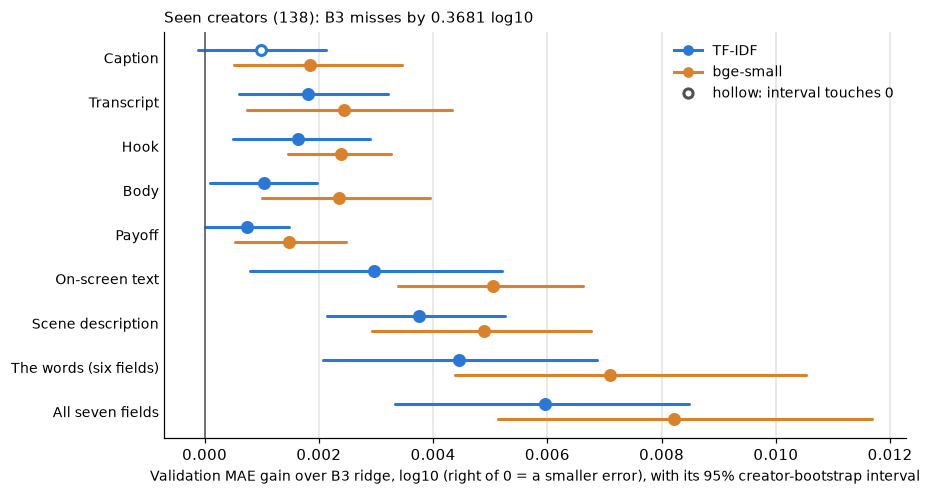

In [12]:
BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#d9822b", "#52514e", "#e4e3df"
order = list(SUBSETS) + ["All seven fields"]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for kind, colour, offset in [("TF-IDF", BLUE, 0.17), ("bge", ORANGE, -0.17)]:
    part = by_field[by_field.features == kind].set_index("fields")
    for y, name in enumerate(reversed(order)):
        r = part.loc[name]
        ax.plot([r.gain_low, r.gain_high], [y + offset] * 2, color=colour, linewidth=2, solid_capstyle="round")
        ax.plot(r.gain, y + offset, "o", markersize=6.5, markeredgewidth=2, color=colour,
                markerfacecolor=colour if r.gain_low > 0 else "white")
ax.axvline(0, color=MUTED, linewidth=1)
ax.grid(axis="x", color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.set_yticks(range(len(order)), list(reversed(order)), fontsize=9)
ax.set_title(f"Seen creators (138): B3 misses by {b3_seen:.4f} log10", loc="left", fontsize=10)
ax.set_xlabel("Validation MAE gain over B3 ridge, log10 (right of 0 = a smaller error), with its 95% "
              "creator-bootstrap interval", fontsize=9)
ax.legend(handles=[
    plt.Line2D([], [], marker="o", color=BLUE, linewidth=2, label="TF-IDF"),
    plt.Line2D([], [], marker="o", color=ORANGE, linewidth=2, label="bge-small"),
    plt.Line2D([], [], marker="o", color=MUTED, markerfacecolor="white", markeredgewidth=2, linestyle="none",
               label="hollow: interval touches 0"),
], loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

**What it says.** Every orange dot sits right of its blue one: bge reads every field a little better than counted
words. The two strongest single fields are on-screen text and the scene description, and the six word fields together
come close to all seven. Every whisker but TF-IDF's caption clears 0. The gains are small next to B3's error: the
largest, +0.0082, is 2.2% of 0.3681.

**What.** Two checks the bar asks for, both on seen creators:

1. **Without reposts.** The all-fields models scored again without the 73 validation videos that have an exact twin
   among the training videos (`has_twin`), against B3 on the same rows.
2. **bge against TF-IDF.** The bge models' gains over the TF-IDF models, all fields, with TF-IDF as the base.

**Why.** A text model can memorise a clip it saw in training and score its repost perfectly; that is not learning
what works. And the second check decides whether stage 4's rental runs a larger text encoder (section 0).

**The mistake it avoids.** Paying for a bigger encoder because the small one looked a little better, when its edge
over a word count is inside the noise.

In [13]:
no_twin = seen_rows & (videos.has_twin == 0).to_numpy()  # has_twin is 0/1: compare, never ~, which flips bits
repost_check = score_table(["TF-IDF ridge", "bge ridge", "TF-IDF logistic", "bge logistic"], no_twin)
repost_check = repost_check[repost_check.metric.isin(["MAE", "roc_auc", "top_decile_share"])]
print(f"Seen creators without reposts: {no_twin.sum():,} videos ({seen_rows.sum() - no_twin.sum()} removed)")
display(repost_check.assign(text=repost_check.apply(cell, axis=1))
        .pivot(index="model", columns="metric", values="text").drop(index="B3 ridge"))

head_to_head = []
for metric_name, (kind_a, kind_b) in {"MAE": ("TF-IDF ridge", "bge ridge"),
                                      "roc_auc": ("TF-IDF logistic", "bge logistic")}.items():
    every = predictions | scores
    metric, lower_is_better = METRICS[metric_name]
    table = paired_creator_bootstrap(metric, lift[seen_rows], {kind_a: every[kind_a][seen_rows],
                                                               kind_b: every[kind_b][seen_rows]},
                                     creator[seen_rows], base=kind_a, lower_is_better=lower_is_better,
                                     n_boot=N_BOOT, seed=SEED)
    r = table.loc[kind_b]
    head_to_head.append({"metric": metric_name, "bge's gain over TF-IDF": f"{r.gain:+.4f} [{r.gain_low:+.4f}, {r.gain_high:+.4f}]",
                         "bge beats TF-IDF": "yes" if r.gain_low > 0 else "no"})
display(pd.DataFrame(head_to_head).set_index("metric"))

Seen creators without reposts: 13,573 videos (73 removed)


metric,MAE,roc_auc,top_decile_share
model,,,
TF-IDF logistic,NaN,"0.576 +0.039 [-0.000, +0.077]","0.342 +0.051 [+0.007, +0.094]"
TF-IDF ridge,"0.3623 +0.0060 [+0.0034, +0.0085]","0.580 +0.044 [+0.011, +0.075]","0.370 +0.078 [+0.036, +0.119]"
bge logistic,NaN,"0.583 +0.046 [+0.009, +0.085]","0.354 +0.062 [+0.016, +0.108]"
bge ridge,"0.3600 +0.0083 [+0.0052, +0.0118]","0.584 +0.047 [+0.013, +0.082]","0.340 +0.048 [+0.005, +0.090]"


,bge's gain over TF-IDF,bge beats TF-IDF
metric,,
MAE,"+0.0023 [+0.0004, +0.0043]",yes
roc_auc,"+0.0067 [-0.0051, +0.0219]",no


**What it says.** Without the 73 reposts, nothing moves: on the 13,573 videos left, TF-IDF ridge gains +0.0060
[+0.0034, +0.0085] over B3 and bge ridge +0.0083 [+0.0052, +0.0118]. The gains are not memorised reposts. The logistic
heads keep their top-10% share gains, but TF-IDF logistic's ROC-AUC gain now touches 0 (+0.039, with a lower end that
rounds to −0.000); bge logistic's holds (+0.046 [+0.009, +0.085]).

bge beats TF-IDF on the bar's metric: its MAE gain over the TF-IDF ridge is +0.0023 [+0.0004, +0.0043], an interval
above 0. Section 0's rule therefore sends a larger text encoder to stage 4's rental (the hand-off names it). On
ROC-AUC the two can't be told apart (+0.0067 [−0.0051, +0.0219]).

## Is the text finding the clips the platform kept?

**What.** The platform keeps each channel's top clips by share rate and retires the rest (trap 3), so kept clips'
lift averages far above retired clips' (printed below). A text model could look good by spotting kept clips through
some quirk of how they were labelled, instead of by reading what works. Two checks, on seen creators, with
`has_video` used only to split the rows, never as a feature:

1. **Given the lift, does the text's correction still know which clips were kept?** A regression, inside each
   creator, of what the text model adds to B3 (its prediction minus B3's) on the kept flag and on the lift itself,
   with a creator-bootstrap interval for the kept flag's coefficient. A model that reads content tracks the lift, and
   knows "kept" only through it: the coefficient should be near 0. A kept-clip detector would keep a large one.
2. **Does it rank videos inside each group?** Spearman inside a creator, among kept clips only and among retired
   clips only. Within a group the kept flag is constant, so a pure kept-clip detector would rank nothing there.

**Why.** The text gain turned out several times larger than anything in stage 2, and a gain that size is the first
thing to distrust (notebook 02, cell 48). The MAE gain within each group can't settle it: B1, an honest baseline,
gains on retired clips and loses on kept ones only because the two groups' mean lifts differ so much.

**The mistake it avoids.** Publishing trap 3 again in a new form. These labels were written by the platform's
pipeline, and the `files` table is not the only way the platform's choices could reach a model.

In [14]:
def kept_given_lift(correction, rows):
    # Inside each creator: correction ~ a * kept + b * lift. Each creator's sums of products are kept apart, so a
    # bootstrap draw just weights them; a is the kept flag's coefficient, with its 95% interval over creator draws.
    codes, _ = pd.factorize(creator[rows])

    def centre(x):
        return x - pd.Series(x).groupby(codes).transform("mean").to_numpy()  # minus the creator's own mean

    k, l, y = centre(kept[rows].astype(float)), centre(lift[rows]), centre(correction[rows])
    sums = {name: np.bincount(codes, a * b) for name, (a, b) in
            {"kk": (k, k), "kl": (k, l), "ll": (l, l), "ky": (k, y), "ly": (l, y)}.items()}
    rng = np.random.default_rng(SEED)
    n = len(sums["kk"])
    weights = np.vstack([np.ones(n)] + [np.bincount(rng.integers(0, n, n), minlength=n) for _ in range(N_BOOT)])
    kk, kl, ll, ky, ly = (weights @ sums[name] for name in ["kk", "kl", "ll", "ky", "ly"])
    a = (ll * ky - kl * ly) / (kk * ll - kl ** 2)  # the 2 x 2 normal equations, solved for the kept coefficient
    alone = ky / kk  # the same, without the lift: how far kept clips' corrections sit above retired ones' anyway
    return a[0], *np.quantile(a[1:], [0.025, 0.975]), alone[0]


print(f"Seen creators' validation videos: kept clips' mean lift {lift[seen_rows & kept].mean():+.3f} "
      f"({(seen_rows & kept).sum():,}), retired clips' {lift[seen_rows & ~kept].mean():+.3f} ({(seen_rows & ~kept).sum():,})")
leak_check = []
for name in ["TF-IDF ridge", "bge ridge"]:
    a, low, high, alone = kept_given_lift(predictions[name] - predictions["B3 ridge"], seen_rows)
    leak_check.append({"model": name, "kept clips' correction, without the lift": f"{alone:+.4f}",
                       "given the lift": f"{a:+.4f} [{low:+.4f}, {high:+.4f}]"})
display(pd.DataFrame(leak_check).set_index("model"))

ranking = {}
for label, rows in {"kept clips": seen_rows & kept, "retired clips": seen_rows & ~kept}.items():
    names = ["B3 ridge", "B1 weighted mean", "TF-IDF ridge", "bge ridge"]
    table = paired_creator_bootstrap(METRICS["spearman_within"][0], lift[rows], {n: predictions[n][rows] for n in names},
                                     creator[rows], base="B3 ridge", n_boot=N_BOOT, seed=SEED)
    ranking[f"Spearman inside a creator, {label} ({rows.sum():,})"] = [
        f"{r.value:.3f} [{r.value_low:.3f}, {r.value_high:.3f}]" for r in table.loc[names].itertuples()]
display(pd.DataFrame(ranking, index=names))

Seen creators' validation videos: kept clips' mean lift +0.215 (4,719), retired clips' -0.128 (8,927)


,"kept clips' correction, without the lift",given the lift
model,,
TF-IDF ridge,+0.0234,"-0.0025 [-0.0097, +0.0047]"
bge ridge,+0.0298,"-0.0093 [-0.0181, -0.0004]"


,"Spearman inside a creator, kept clips (4,719)","Spearman inside a creator, retired clips (8,927)"
B3 ridge,"0.034 [-0.014, 0.079]","0.052 [0.018, 0.088]"
B1 weighted mean,"0.242 [0.180, 0.309]","0.215 [0.171, 0.259]"
TF-IDF ridge,"0.082 [0.022, 0.144]","0.149 [0.106, 0.189]"
bge ridge,"0.121 [0.060, 0.180]","0.186 [0.146, 0.225]"


**What it says.** Kept clips beat their creator's median by +0.215 log10 on average and retired ones fall short by 0.128,
so a model that spotted kept clips would look good. Neither text model does:

- **Given the lift, the correction doesn't know which clips were kept.** Without the lift, kept clips' corrections sit
  higher (+0.0234 for TF-IDF, +0.0298 for bge), as they should if the words track lift. With the lift in the
  regression, the kept flag's coefficient is −0.0025 [−0.0097, +0.0047] for TF-IDF, at 0, and −0.0093 [−0.0181,
  −0.0004] for bge, slightly below 0: at the same lift, bge rates kept clips a little lower, the opposite of what a
  kept-clip detector would do.
- **Both rank videos inside each group,** where the kept flag is constant: Spearman inside a creator 0.082 [0.022,
  0.144] (TF-IDF) and 0.121 [0.060, 0.180] (bge) among kept clips, and 0.149 [0.106, 0.189] and 0.186 [0.146, 0.225]
  among retired ones, against B3's 0.034 and 0.052. A kept-clip detector would rank nothing there.

The text models read content. Recent form ranks inside both groups better still (0.242 and 0.215): it is a different
signal, the creator's recent run, and stage 5 can use both.

## The verdict, against section 0's bar

**What.** Apply the bar as written, in code: the primary test on the seen creators' MAE gain over B3, the repost
check, the secondary tests for the logistic heads, and bge against TF-IDF.

**Why.** The verdict is computed, not read off the chart, so it can't be bent toward a pass.

**The mistake it avoids.** Calling a gain whose interval touches 0 a small win. It is "the words add nothing beyond
B3".

In [15]:
seen_table = results["seen"].set_index(["metric", "model"])
repost_table = repost_check.set_index(["metric", "model"])


def above(table, metric, model):
    # The bar's test: the lower end of the gain's 95% interval is above 0
    return "yes" if table.loc[(metric, model), "gain_low"] > 0 else "no"


verdicts = {}
for kind in ["TF-IDF", "bge"]:
    mae = seen_table.loc[("MAE", f"{kind} ridge")]
    logistic = f"{kind} logistic"
    verdicts[kind] = {
        "MAE gain over B3, seen": f"{mae.gain:+.4f} [{mae.gain_low:+.4f}, {mae.gain_high:+.4f}]",
        "typical error": f"{'shrinks' if mae.gain > 0 else 'grows'} by {abs(100 * mae.gain / seen_table.loc[('MAE', 'B3 ridge'), 'value']):.2f}%",
        "beats the bar": above(seen_table, "MAE", f"{kind} ridge"),
        "still without reposts": above(repost_table, "MAE", f"{kind} ridge"),
        # Section 0: a pass must hold without the reposts, the secondary bar's too
        "logistic: ROC-AUC above B3 (with / without reposts)":
            f"{above(seen_table, 'roc_auc', logistic)} / {above(repost_table, 'roc_auc', logistic)}",
        "logistic: top-10% share above B3 (with / without reposts)":
            f"{above(seen_table, 'top_decile_share', logistic)} / {above(repost_table, 'top_decile_share', logistic)}",
        "new: interval above 0": "yes" if results["new"].query("metric == 'MAE' and model == @kind + ' ridge'")
                                          .gain_low.iloc[0] > 0 else "no",
        "held out: interval above 0": "yes" if results["holdout"].query("metric == 'MAE' and model == @kind + ' ridge'")
                                                .gain_low.iloc[0] > 0 else "no",
    }
verdicts = pd.DataFrame(verdicts).T
display(verdicts)
passing = [k for k in verdicts.index if verdicts.loc[k, "beats the bar"] == "yes" and verdicts.loc[k, "still without reposts"] == "yes"]
print(f"Beat the bar (seen creators, with and without reposts): {', '.join(passing) if passing else 'none'}")
print(f"bge beats TF-IDF (MAE, seen creators, cell 39): {head_to_head[0]['bge beats TF-IDF']}")

,"MAE gain over B3, seen",typical error,beats the bar,still without reposts,logistic: ROC-AUC above B3 (with / without reposts),logistic: top-10% share above B3 (with / without reposts),new: interval above 0,held out: interval above 0
TF-IDF,"+0.0060 [+0.0033, +0.0085]",shrinks by 1.62%,yes,yes,yes / no,yes / yes,yes,yes
bge,"+0.0082 [+0.0051, +0.0117]",shrinks by 2.23%,yes,yes,yes / yes,yes / yes,yes,yes


Beat the bar (seen creators, with and without reposts): TF-IDF, bge
bge beats TF-IDF (MAE, seen creators, cell 39): yes


**What it says.** Against the bar as written:

- **TF-IDF beats B3 for seen creators:** +0.0060 [+0.0033, +0.0085], an error 1.62% smaller, and still without the
  reposts. Its logistic head passes the secondary bar with the reposts, and without them keeps the top-10% share but
  not the ROC-AUC, whose interval touches 0 by a hair. Under the bar, that is a miss on ROC-AUC.
- **bge-small beats B3 for seen creators:** +0.0082 [+0.0051, +0.0117], an error 2.23% smaller, still without the
  reposts, and its logistic head passes both secondary tests with and without them.
- **bge-small beats TF-IDF** (+0.0023 [+0.0004, +0.0043], cell 39), so stage 4's rental runs a larger text encoder.
- **New and held-out creators,** not required to pass, clear 0 with both models.

The words add something real beyond the creator's history and the video's length, about twelve times what metadata
added over zero lift in stage 2 (0.0007). It is still small: the typical miss goes from a factor of 2.33 to 2.29.

## 8. What the text model learned

**What.** The TF-IDF ridge head's weights, all fields together, read as words. For each term: its field, how many of
the 148 training creators use it (at least 20, by construction), how many training videos, and its effect: the
weight times the term's typical TF-IDF value where it appears, in log10 of lift and as a share rate. The 12 terms
that push the prediction up most and the 12 that push it down most, then the field flags.

**Why.** A weight on a word that 20 creators use is a pattern, not a quote: it can be shown under rule 9, and it
says what the model learned in words a person can check. The bge model's 2,688 numbers can't be read this way.

**The mistake it avoids.** Showing a word that names someone, or a phrase only one video says. Every term here
passed the 20-creator rule before the model saw a label, and nothing is shown from any single video.

In [16]:
weights = tfidf_ridge.coef_  # flags first (7), then each field's terms, in the order they were stacked
flag_weights = pd.Series(weights[:len(FIELDS)], index=[text.FIELDS[f] for f in FIELDS])
learned, start = [], len(FIELDS)
for field in FIELDS:
    vocabulary = vocabularies[field]
    block = tfidf[field][training]
    w = weights[start:start + len(vocabulary)]
    start += len(vocabulary)
    videos_using = np.diff(block.tocsc().indptr)  # training videos with the term
    totals = np.asarray(block.sum(axis=0)).ravel()
    typical = np.divide(totals, videos_using, out=np.zeros_like(totals), where=videos_using > 0)  # mean weight where used
    learned.append(pd.DataFrame({"field": text.FIELDS[field], "term": vocabulary.index, "creators": vocabulary.values,
                                 "training videos": videos_using, "effect": w * typical}))
learned = pd.concat(learned, ignore_index=True)
assert learned.creators.min() >= text.MIN_CREATORS  # rule 9, checked again on what is about to be shown
learned["as share rate"] = (100 * (10 ** learned.effect - 1)).map("{:+.1f}%".format)
show = ["field", "term", "creators", "training videos", "effect", "as share rate"]
print("Pushes the predicted lift up most:")
display(learned.nlargest(12, "effect")[show].round({"effect": 4}).reset_index(drop=True))
print("Pushes it down most:")
display(learned.nsmallest(12, "effect")[show].round({"effect": 4}).reset_index(drop=True))
print("The field flags (weight on 'the field holds text', log10 of lift):")
display(flag_weights.round(4).to_frame("weight").T)
print(f"Terms in the model: {len(learned):,}; the largest effect is {learned.effect.abs().max():.4f} log10, "
      f"against B3's MAE of {b3_seen:.4f}")

Pushes the predicted lift up most:


,field,term,creators,training videos,effect,as share rate
0,On-screen text,da,28,728,0.0708,+17.7%
1,Caption,ib,24,687,0.0624,+15.4%
2,Caption,netflix,20,398,0.0607,+15.0%
3,Caption,movies,25,304,0.0524,+12.8%
4,Caption,send,44,156,0.0523,+12.8%
5,On-screen text,bestie,34,276,0.0505,+12.3%
6,On-screen text,friend,84,1858,0.0463,+11.3%
7,Caption,bestie,34,133,0.0456,+11.1%
8,Caption,dancing,30,276,0.0429,+10.4%
9,On-screen text,send,46,202,0.0392,+9.5%


Pushes it down most:


,field,term,creators,training videos,effect,as share rate
0,Caption,ad,36,309,-0.1379,-27.2%
1,Caption,duet with,53,707,-0.0849,-17.8%
2,Caption,shoes,31,70,-0.0817,-17.1%
3,Caption,code,26,339,-0.0789,-16.6%
4,Caption,duet,57,858,-0.0754,-15.9%
5,Caption,filter,37,124,-0.0637,-13.6%
6,Caption,ai,26,68,-0.0609,-13.1%
7,Caption,podcast,21,237,-0.0595,-12.8%
8,Caption,na,29,713,-0.0561,-12.1%
9,On-screen text,filter,27,74,-0.0559,-12.1%


The field flags (weight on 'the field holds text', log10 of lift):


,Caption,Transcript,Hook,Body,Payoff,On-screen text,Scene description
weight,0.0091,-0.0169,0.002,0.0073,0.0183,-0.0124,0.0021


Terms in the model: 39,481; the largest effect is 0.1379 log10, against B3's MAE of 0.3681


**What it says.** In words that at least 20 creators use, the TF-IDF model learned:

- **Share prompts and friendship push the prediction up:** "send" (in captions, +12.8%, and on screen, +9.5%), "this
  to", "bestie", "friend" (used by 84 creators). So do films ("netflix", "movies"), "dancing", and "ib", the "inspired
  by" credit line.
- **Ads push it down most:** "ad" in a caption (−27.2%, the largest effect of all 39,481 terms) and "code". So do
  formats borrowed from the platform, "duet with" and "duet", "challenge", "trend", "filter" (in captions and on screen),
  and "podcast", "ai" and "shoes".
- **Two terms aren't English.** "da" in on-screen text (the strongest push up, +17.7%) and "na" in captions are
  Serbian words, from on-screen text the pipeline left untranslated and from captions, which are never translated.
  They mark a language, not a subject.

No term is a person's name. Every effect is small next to B3's error: the largest is 0.1379 log10, against 0.3681, and
a video carries many terms. The field flags are what a field's presence adds on top of its words, all within ±0.02.

## What stage 3 found

- **The words add to the baseline, and the gain holds.** For seen creators, B3 ridge misses by 0.3681 log10. Sentence
  embeddings of the seven text fields (bge-small), in ridge on top of B3, cut that by 0.0082 [0.0051, 0.0117]: an
  error 2.2% smaller. TF-IDF of the words at least 20 creators use cuts it by 0.0060 [0.0033, 0.0085]. Both hold
  without the 73 reposts, and both clear 0 for new and held-out creators too, which nothing in stage 2 did. Small, and
  about twelve times what metadata added over zero lift.
- **Meaning beats counted words, by a little.** bge-small beats TF-IDF by 0.0023 [0.0004, 0.0043] in MAE, and in every
  field alone, but not in breakout ROC-AUC. Under the bar, that earns a larger encoder on stage 4's GPU.
- **The words rank videos too.** bge's correction lifts the Spearman inside a creator from B3's 0.071 to 0.218, above
  recent form's 0.146. Of each creator's top tenth by the TF-IDF model, 36.8% broke out, against 29.0% for B3 and
  24.7% for zero lift. Recent form still has the best breakout ROC-AUC (0.588), so the two signals differ.
- **Where the signal is.** Alone, on-screen text (+0.0051) and the scene description (+0.0049) are the strongest
  fields, both produced by the vision-language model (trap 5): the creator's words read off the frames, and the
  model's reading of the picture. The six word fields without the scene description get most of the gain (+0.0071 of
  +0.0082); the scene description adds about 0.001 on top. Inside a creator, a video with text on screen beats one
  without by 15%.
- **What the words say.** Share prompts and friendship push the prediction up ("send", "this to", "bestie",
  "friend"); ads push it down most ("ad", −27%; "code"), and so do borrowed formats: duets, challenges, trends,
  filters. Two strong terms mark a language (Serbian), not a subject.
- **Not a leak.** Given a clip's lift, neither model's correction knows whether the platform kept it (TF-IDF −0.0025
  [−0.0097, +0.0047]; bge slightly below 0, the opposite of a detector), and both rank videos among kept clips alone
  and among retired clips alone.

The test split was never loaded in this notebook.

## The hand-off

**To stage 5: bge ridge, all seven fields, on top of B3.** It is the passing model with the largest MAE gain for seen
creators (+0.0082 [+0.0051, +0.0117]).

- **Features:** for each of the seven fields, `BAAI/bge-small-en-v1.5`'s 384 numbers for its first 256 tokens (unit
  length; zeros when the field is empty), plus the seven "the field holds text" flags: 2,695 columns.
- **Model:** ridge with alpha 100, fitted on the training cell (74,552 videos, 148 creators) to what B3 leaves; the
  prediction is B3 ridge (no hour, alpha 0.1, notebook 02 cell 24) plus the head. For ranking breakouts, the logistic
  head on B3's standardised prediction and the same columns, C 0.1. bge has no vocabulary.
- **The readable runner-up:** TF-IDF ridge, alpha 100, over the seven per-field vocabularies of the words and word
  pairs at least 20 training creators use (`text.fit_tfidf` on the training cell rebuilds them exactly). Section 8's
  words are its.
- **If stage 4's larger encoder passes its bar** (below), it replaces bge-small here, with its alpha chosen on
  validation by the same `ridge_head`.

**What stage 5 must compute.**

- **Out-of-fold text predictions for the training rows, if it stacks them.** The head here was fitted on every
  training row, so its predictions there have seen their own labels, and a stacker trained on them would trust the
  text too much. Refit B3 and the head in folds grouped by creator (each training creator's videos in one fold, alpha
  fixed at 100), so each training row is predicted by a model that never saw its creator. Validation and test rows get
  the full fit's predictions.
- **The test texts' features, when it opens the test.** `text.embed` on the test rows' seven fields: the cache is keyed
  by the text, so only texts not seen here get embedded. The test holds 21,740 videos (docs/why-the-rules.md), about a sixth
  as many as here, so under an hour at this fill's 44 texts a second. For TF-IDF, the training-fitted vectorizers' `transform`. Nothing
  is refitted on the test.

**The text job for stage 4's rental.** bge-small beat TF-IDF, so the rental runs one larger encoder:

- **The encoder: `Qwen/Qwen3-Embedding-4B`, cut to 1,024 numbers** (its Matryoshka training makes the first 1,024 a
  usable embedding). bge-small's edge over counted words is small (+0.0023), so the step up should be a big one: this
  is the largest encoder my content platform's GPU box already serves, a hundred times bge-small's size. 1,024 numbers
  a field keeps the heads on this laptop (7,175 columns). It needs a card with 24 GB or more.
- **Settings, bge-small's, so only the encoder changes:** the first 256 tokens, unit length, no instruction (Qwen3's
  instruction is for search queries).
- **Inputs:** every distinct non-empty text of the seven fields over the target videos, train, validation and test,
  each named by an opaque id (the md5 of the text), with no username, video id, creator, split or label. The test
  texts go in the same way the test frames do, blind: their vectors are read only when stage 5 opens the test. The
  texts themselves must go up, so the box is destroyed after the job (rule 9).
- **Output:** the vectors in `text.embed`'s cache format (md5 keys, float32 parts) under
  `data/embeddings/Qwen--Qwen3-Embedding-4B/`, so `text.embed(..., model_name="Qwen/Qwen3-Embedding-4B")` reads them
  with no code change.
- **Its bar, written now, before it runs (rule 7):** Qwen3-Embedding-4B replaces bge-small if the 95% paired
  creator-bootstrap interval of its ridge head's validation MAE gain over bge ridge (both on top of B3, the same heads
  and rows, 2,000 draws, seed 2026) lies above 0 for seen creators, with and without the reposts. Otherwise bge-small
  stays. Stage 4's notebook scores it first, before any image model, because the best of stage 3 is what the pixels
  must beat.